# 08 · Controllability, observability and pole placement

State feedback u = −Kx moves every closed-loop pole wherever one wants - if the system is controllable. The
dual property, observability, decides whether the state can be reconstructed from the output. This notebook
tests both (rank, singular values, the PBH test), shows what an uncontrollable or unobservable mode looks like
and why a cancelled unstable mode is a catastrophe, places poles by Ackermann's formula and by the Sylvester
method, and ends with the numerical warning every placement routine should carry.

**What you will learn**
- test controllability and observability by rank, singular values and the PBH test
- explain hidden modes and why unstable cancellations are forbidden
- place poles with Ackermann's formula and the Sylvester method
- recognise the ill-conditioning of pole placement in high order

**Before you start:** notebooks 00 and 01  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from englincontrol import systems as sy, statespace as sp, response as rs, models, polynomials as pl
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## The tests

In [2]:
cp = models.cart_pendulum()["system"]
c = sp.controllability(cp.A, cp.B); o = sp.observability(cp.A, cp.C); o_pos = sp.observability(cp.A, cp.C[[0]]); o_ang = sp.observability(cp.A, cp.C[[1]])
print(f"cart-pendulum: controllable from the force ({c['rank']} of 4; singular values {np.round(c['singular_values'], 2)})")
print(f"  observable from position and angle: {o['observable']}; from position alone: {o_pos['observable']}; from the angle alone: {o_ang['observable']} (rank {o_ang['rank']})")
A_un = np.array([[-1.0, 0.0], [0.0, -2.0]]); B_un = np.array([[1.0], [0.0]])
print(f"\ndiag(-1, -2) with B = [1, 0]: rank {sp.controllability(A_un, B_un)['rank']}; PBH test names the uncontrollable mode: {sp.pbh_test(A_un, B_un)['uncontrollable_modes']}")

cart-pendulum: controllable from the force (4 of 4; singular values [159.7  127.23   1.52   1.33])
  observable from position and angle: True; from position alone: True; from the angle alone: False (rank 3)

diag(-1, -2) with B = [1, 0]: rank 1; PBH test names the uncontrollable mode: [-2.]


The cart-pendulum is controllable from the single force and observable from both outputs - but not from the
angle alone: the cart's position never shows in the angle, so it cannot be estimated from it (and a controller
that only measures the angle cannot keep the cart in place). The PBH test gives more than a rank: it names the
mode that is out of reach, here the eigenvalue −2 whose eigenvector is orthogonal to B.

## What a hidden mode means: the cancelled unstable pole

In [3]:
P = sy.tf([1.0, -1.0], [1.0, 1.0, -2.0])                    # (s - 1) / ((s - 1)(s + 2)): the unstable pole cancels on paper
print("transfer function after cancellation:", P, "-> looks like a harmless 1/(s + 2)")
Pss = sy.ss(np.array([[1.0, 0.0], [0.0, -2.0]]), [[1.0], [1.0]], [[0.0, 3.0]], 0.0)      # a realisation that keeps both modes
print("its full realisation has poles", np.round(Pss.poles(), 3), "and an unobservable mode:", sp.observability(Pss.A, Pss.C)["rank"], "observable of 2")
t, y, x = rs.initial(Pss, [1e-6, 0.0], 15.0)
print(f"a 1e-6 perturbation of the hidden state grows to {x[-1, 0]:.0f} by t = 15 while the output stays {np.max(np.abs(y)):.1e}: the output sees nothing of the explosion")

transfer function after cancellation: TransferFunction(s - 1 / s^2 + s - 2) -> looks like a harmless 1/(s + 2)
its full realisation has poles [ 1. -2.] and an unobservable mode: 1 observable of 2
a 1e-6 perturbation of the hidden state grows to 3 by t = 15 while the output stays 0.0e+00: the output sees nothing of the explosion


On paper (s − 1)/((s − 1)(s + 2)) cancels to 1/(s + 2); in the physical system the unstable mode is still there,
unobservable from the output, growing from any perturbation while the output reports all is well. Cancelling an
unstable pole with a controller zero produces exactly this: internal instability behind a healthy-looking
transfer function. The rule is absolute: never cancel right-half-plane poles or zeros, and check minimality
of what remains.

## Pole placement: Ackermann and beyond

K = [[ -5.382  -4.765 -27.06   -5.166]] 
closed-loop poles: [-6.+0.j -5.+0.j -2.-2.j -2.+2.j]


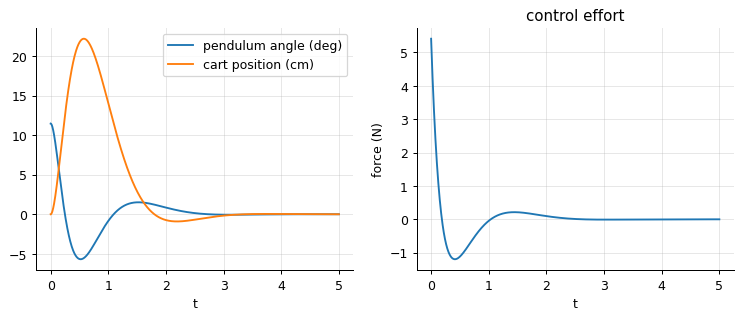


two inputs, five states (Sylvester method): poles [-5.+0.j -3.-2.j -3.+2.j -2.+0.j -1.+0.j] - the gain is not unique; the method picks a small one


In [4]:
A, B, C = cp.A, cp.B, cp.C
desired = np.array([-2 + 2j, -2 - 2j, -5.0, -6.0])
K = sp.place(A, B, desired)
print("K =", np.round(K, 3), "\nclosed-loop poles:", np.round(np.sort_complex(np.linalg.eigvals(A - B @ K)), 6))
Acl = sy.ss(A - B @ K, B, C, np.zeros((2, 1)))
t, y, x = rs.initial(Acl, [0.0, 0.0, 0.2, 0.0], 5.0)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(t, np.degrees(x[:, 2]), label="pendulum angle (deg)"); axes[0].plot(t, 100 * x[:, 0], label="cart position (cm)"); axes[0].legend(); axes[0].set_xlabel("t")
axes[1].plot(t, (-x @ K.T)[:, 0]); axes[1].set_ylabel("force (N)"); axes[1].set_xlabel("t"); axes[1].set_title("control effort")
plt.show()
rng = np.random.default_rng(2)
A5, B5 = rng.normal(size=(5, 5)), rng.normal(size=(5, 2))
des5 = np.array([-1, -2, -3 + 2j, -3 - 2j, -5])
K5 = sp.place(A5, B5, des5)
print("\ntwo inputs, five states (Sylvester method): poles", np.round(np.sort_complex(np.linalg.eigvals(A5 - B5 @ K5)), 6), "- the gain is not unique; the method picks a small one")

With the four poles chosen, Ackermann's formula gives the single gain vector that produces them; the pendulum
released at 11° is brought upright in two seconds with a cart excursion of a few centimetres and a peak force
of a few newtons. With two inputs the gain matrix is no longer unique: the Sylvester-equation method chooses a
parameter matrix at random and solves for K, and the freedom can be spent on small gains or robust eigenvectors.

## The numerical warning

In [5]:
for n in (4, 8, 12, 16):
    A_ = np.diag(np.arange(1, n + 1, dtype=float))                     # distinct, spread eigenvalues
    B_ = np.ones((n, 1))
    des = -np.arange(1, n + 1, dtype=float)
    K_ = sp.acker(A_, B_, des)
    got = np.sort(np.linalg.eigvals(A_ - B_ @ K_).real)
    print(f"n = {n:2d}: controllability matrix condition number {np.linalg.cond(sp.ctrb(A_, B_)):.1e}; largest pole error {np.max(np.abs(got - np.sort(des))):.1e}; |K| {np.max(np.abs(K_)):.1e}")

n =  4: controllability matrix condition number 1.2e+03; largest pole error 3.5e-11; |K| 4.2e+02
n =  8: controllability matrix condition number 9.5e+08; largest pole error 2.6e-02; |K| 5.0e+05
n = 12: controllability matrix condition number 7.0e+15; largest pole error 1.8e+01; |K| 5.8e+08
n = 16: controllability matrix condition number 3.5e+20; largest pole error 3.7e+03; |K| 4.3e+11


Ackermann's formula inverts the controllability matrix, whose condition number grows exponentially with the
order: by n = 12 the placed poles are wrong in the first digits and by 16 the computation has lost its meaning,
with gains of 10¹³ that no actuator could deliver. The lesson is twofold: use Ackermann only for small
systems (the library does, and switches to the Sylvester method otherwise), and distrust any pole placement
whose gains are enormous - the specification was unreasonable, not the arithmetic. LQR (notebook 10) chooses
poles the actuator can afford.

## Inside the algorithm: Ackermann's formula by hand

In [6]:
A2, B2 = np.array([[0.0, 1.0], [0.0, 0.0]]), np.array([[0.0], [1.0]])     # double integrator
phi = pl.from_roots([-2.0, -3.0])                                             # desired (s + 2)(s + 3) = s^2 + 5 s + 6
phiA = A2 @ A2 + phi[1] * A2 + phi[2] * np.eye(2)
Wc = np.hstack([B2, A2 @ B2])
K_hand = np.array([0.0, 1.0]) @ np.linalg.inv(Wc) @ phiA
print("K by hand:", K_hand, " library:", sp.place(A2, B2, [-2.0, -3.0]).ravel(), " -> closed-loop poles", np.round(np.linalg.eigvals(A2 - B2 @ K_hand.reshape(1, 2)), 6))

K by hand: [6. 5.]  library: [6. 5.]  -> closed-loop poles [-2. -3.]


## Exercises
1. For the cart-pendulum, place the poles at (-1 +- j, -2, -3), (-2 +- 2j, -5, -6) and (-4 +- 4j, -10, -12); simulate the recovery from 10 degrees and tabulate the settling time, the peak force and the cart excursion. Where does the actuator (say 10 N) rule out the design?
2. The quarter car (`models.quarter_car`) has two inputs; is it controllable from the actuator force alone? From the road alone? Use the PBH test to name any mode that cannot be moved.
3. **Implement it yourself:** place the poles of the 5-state random system by the Sylvester method yourself (choose G, solve A X - X Lambda = B G with `linalg.sylvester`, K = G X^-1) and verify the closed-loop eigenvalues; try two different G and compare the gains.